# Breast cancer classification

Use the 569-row Wisconsin Diagnostic Breast Cancer dataset bundled with scikit-learn. The 30 numeric features describe cell nuclei in digitized fine-needle-aspirate images, not ordinary symptom checklists. The target is explicitly recoded as malignant=1 and benign=0 so recall refers to malignant cases.

An 80/20 stratified split leaves 114 held-out records. Five-fold training-only ROC-AUC selects between standardized logistic regression and a random forest. Standardization and imputation are fitted inside each training fold. A majority baseline is included. Even high test performance on this small, familiar dataset is not clinical validation. It can miss malignant cases. It is a classroom classification project, not a diagnosis, screening tool, medical device or advice for patients.

Prepared with AI assistance for review. This notebook has been run, but no internship submission is claimed.

## Reproducible implementation

The source below uses seed 42, a training-only validation process and a held-out test set. Install requirements.txt before running. Run all cells from this project folder.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
 RocCurveDisplay, mean_absolute_error, mean_squared_error, r2_score)
BASE=Path.cwd()
OUT=BASE/"results"
OUT.mkdir(exist_ok=True)
SEED=42

def classify(X, y, names, title):
    assert len(X)==len(y) and not pd.Series(y).isna().any()
    # Exclude contradictory labels for identical feature profiles, then collapse duplicates.
    frame=X.reset_index(drop=True).copy()
    frame["__target"]=np.asarray(y)
    keys=list(X.columns)
    conflicts=frame.groupby(keys,dropna=False)["__target"].transform("nunique")>1
    raw_rows=len(frame)
    frame=frame.loc[~conflicts].drop_duplicates(subset=keys).reset_index(drop=True)
    y=frame.pop("__target").to_numpy()
    X=frame
    quality={"input_rows":raw_rows,"conflicting_profile_rows_removed":int(conflicts.sum()),"duplicate_rows_removed":raw_rows-int(conflicts.sum())-len(frame),"analysis_rows":len(frame)}
    (OUT/"data_quality.json").write_text(json.dumps(quality,indent=2))
    indices=np.arange(len(y))
    train_idx,test_idx=train_test_split(indices,test_size=.2,stratify=y,random_state=SEED)
    assert not set(train_idx)&set(test_idx)
    Xtrain,Xtest=X.iloc[train_idx],X.iloc[test_idx]
    ytrain,ytest=np.asarray(y)[train_idx],np.asarray(y)[test_idx]
    models={"baseline":DummyClassifier(strategy="most_frequent"),
            "logistic":make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=3000,random_state=SEED)),
            "forest":make_pipeline(SimpleImputer(strategy="median"),RandomForestClassifier(n_estimators=120,min_samples_leaf=4,class_weight="balanced",random_state=SEED,n_jobs=2))}
    multiclass=len(names)>2
    scoring="f1_macro" if multiclass else "roc_auc"
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    cvresults={}
    for name,model in models.items():
        scores=cross_val_score(model,Xtrain,ytrain,cv=cv,scoring=scoring,n_jobs=1)
        cvresults[name]={"mean":float(scores.mean()),"std":float(scores.std())}
    winner=max((k for k in models if k!="baseline"),key=lambda k:cvresults[k]["mean"])
    rows=[]
    for name in ["baseline",winner]:
        model=models[name].fit(Xtrain,ytrain)
        pred=model.predict(Xtest)
        p=model.predict_proba(Xtest)
        avg="macro" if multiclass else "binary"
        row={"model":name,"accuracy":accuracy_score(ytest,pred),"precision":precision_score(ytest,pred,average=avg,zero_division=0),"recall":recall_score(ytest,pred,average=avg,zero_division=0),"f1":f1_score(ytest,pred,average=avg,zero_division=0)}
        if not multiclass:
            row.update(roc_auc=roc_auc_score(ytest,p[:,1]),average_precision=average_precision_score(ytest,p[:,1]))
        rows.append(row)
        if name==winner:
            fig,ax=plt.subplots(figsize=(6,5))
            ConfusionMatrixDisplay.from_predictions(ytest,pred,display_labels=names,ax=ax,colorbar=False,cmap="Blues")
            ax.set_title(title+" | held-out test")
            fig.tight_layout(); fig.savefig(OUT/"confusion_matrix.png",dpi=160);plt.close(fig)
            if not multiclass:
                fig,ax=plt.subplots(figsize=(6,5)); RocCurveDisplay.from_predictions(ytest,p[:,1],ax=ax)
                ax.plot([0,1],[0,1],"--",color="gray");ax.set_title(title+" | ROC");ax.legend([f"ROC-AUC = {roc_auc_score(ytest,p[:,1]):.4f}"],loc="lower right")
                fig.tight_layout();fig.savefig(OUT/"roc_curve.png",dpi=160);plt.close(fig)
            pd.DataFrame({"source_row":test_idx,"actual":ytest,"predicted":pred}).to_csv(OUT/"test_predictions.csv",index=False)
    result={"rows":len(y),"train_rows":len(train_idx),"test_rows":len(test_idx),"seed":SEED,"positive_class":None if multiclass else names[1],"cv_metric":scoring,"cv_train_only":cvresults,"selected_model":winner,"held_out":rows,"class_counts":pd.Series(y).value_counts().sort_index().to_dict()}
    (OUT/"metrics.json").write_text(json.dumps(result,indent=2))
    pd.DataFrame(rows).to_csv(OUT/"metrics.csv",index=False)
    print(json.dumps(result,indent=2))
    return result

from sklearn.datasets import load_breast_cancer
data=load_breast_cancer(as_frame=True)
X=data.data
# scikit-learn uses 0=malignant; recode so clinical risk is the positive class.
y=(data.target==0).astype(int)
result=classify(X,y,["Benign","Malignant"],"Breast cancer classification")


{
  "rows": 569,
  "train_rows": 455,
  "test_rows": 114,
  "seed": 42,
  "positive_class": "Malignant",
  "cv_metric": "roc_auc",
  "cv_train_only": {
    "baseline": {
      "mean": 0.5,
      "std": 0.0
    },
    "logistic": {
      "mean": 0.9957688338493291,
      "std": 0.004665698474904977
    },
    "forest": {
      "mean": 0.9883384932920537,
      "std": 0.005834177100145485
    }
  },
  "selected_model": "logistic",
  "held_out": [
    {
      "model": "baseline",
      "accuracy": 0.631578947368421,
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "roc_auc": 0.5,
      "average_precision": 0.3684210526315789
    },
    {
      "model": "logistic",
      "accuracy": 0.9649122807017544,
      "precision": 0.975,
      "recall": 0.9285714285714286,
      "f1": 0.9512195121951219,
      "roc_auc": 0.996031746031746,
      "average_precision": 0.994273631904294
    }
  ],
  "class_counts": {
    "0": 357,
    "1": 212
  }
}


## Read the result

| Model | accuracy | precision | recall | f1 | roc_auc | average_precision |
|---|---:|---:|---:|---:|---:|---:|
| baseline | 0.6316 | 0.0000 | 0.0000 | 0.0000 | 0.5000 | 0.3684 |
| logistic | 0.9649 | 0.9750 | 0.9286 | 0.9512 | 0.9960 | 0.9943 |


Do not confuse a good benchmark score with real-world validation. Compare with the baseline and read the limits above.

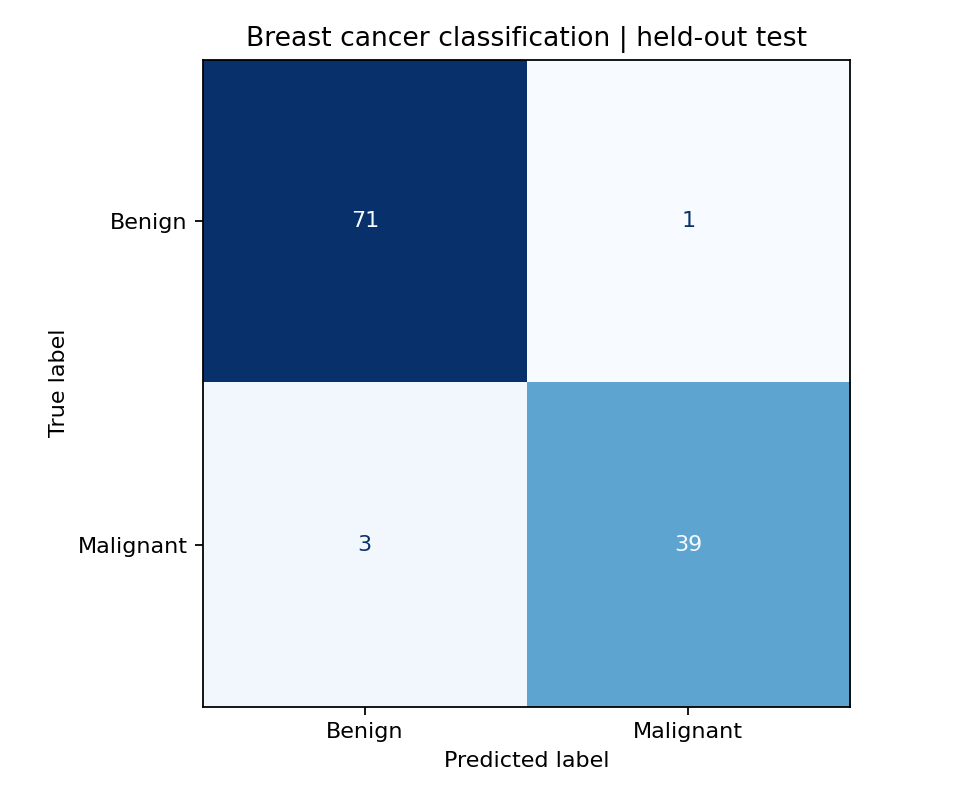

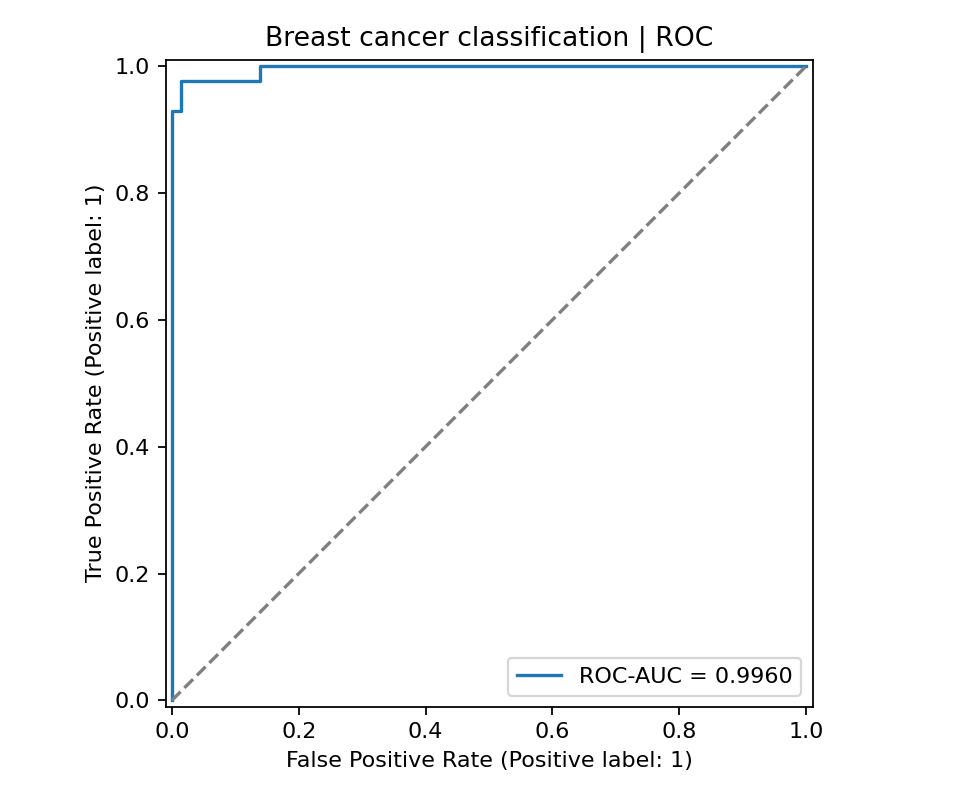

In [2]:
from IPython.display import display, Image
for image in sorted(OUT.glob("*.png")):
    display(Image(filename=str(image)))

## Sources and next steps

https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

Review the README, rerun the tests and practice explaining the work before recording the required video. No LinkedIn post, GitHub publication or submission has been made by this notebook.